In [1]:
import os, time, warnings
import numpy as np, cv2
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import data
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
OUT = "lab07_outputs"; os.makedirs(OUT, exist_ok=True)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

def show(ax, img, title=""):
    ax.imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap="gray")
    ax.set_title(title); ax.axis("off")

# Sample image bundled with scikit-image (RGB -> BGR for OpenCV)
astro = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)   # <-- your image: cv2.imread("path.jpg")
astro = cv2.resize(astro, (320, 320))
print("Sample image:", astro.shape)

OpenCV 4.13.0 | NumPy 2.4.4
Sample image: (320, 320, 3)


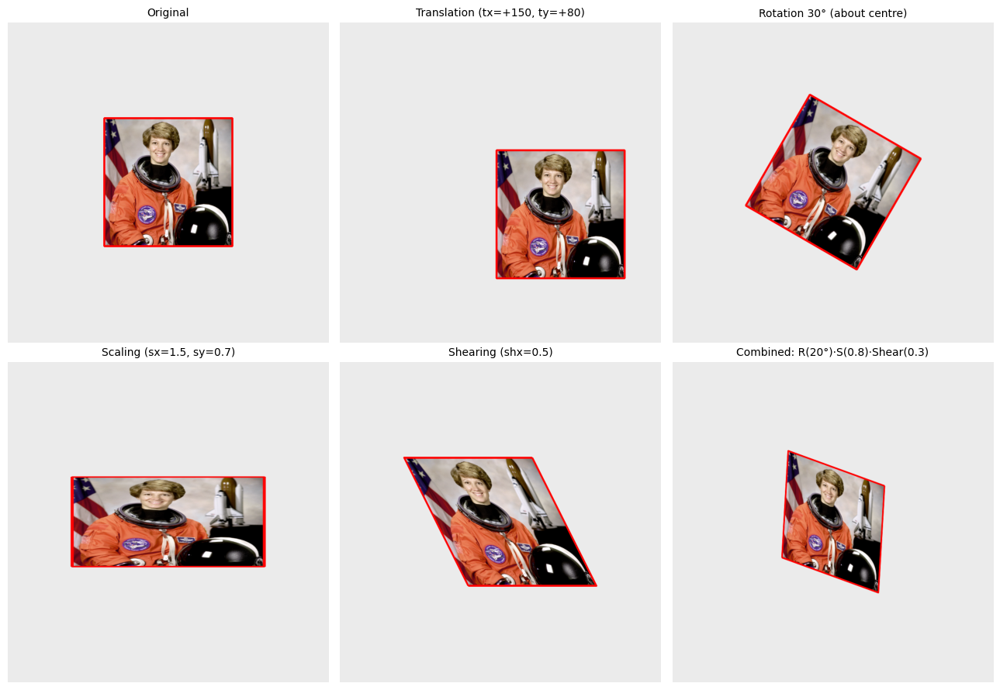

Transform                                  area ratio   det(A)
Original                                        1.000    1.000
Translation (tx=+150, ty=+80)                   1.000    1.000
Rotation 30° (about centre)                     1.000    1.000
Scaling (sx=1.5, sy=0.7)                        1.050    1.050
Shearing (shx=0.5)                              1.000    1.000
Combined: R(20°)·S(0.8)·Shear(0.3)              0.640    0.640


In [2]:
CANVAS = 800
canvas0 = np.full((CANVAS, CANVAS, 3), 235, np.uint8)
h, w = astro.shape[:2]
ox, oy = (CANVAS - w)//2, (CANVAS - h)//2
canvas0[oy:oy+h, ox:ox+w] = astro
cv2.rectangle(canvas0, (ox, oy), (ox+w-1, oy+h-1), (0, 0, 255), 3)      # red border to see the shape clearly
centre = np.array([CANVAS/2, CANVAS/2])
corners0 = np.float32([[ox, oy], [ox+w, oy], [ox+w, oy+h], [ox, oy+h]])

def T(tx, ty):   return np.array([[1,0,tx],[0,1,ty],[0,0,1]], np.float64)
def R(deg):
    a = np.deg2rad(deg); return np.array([[np.cos(a),-np.sin(a),0],[np.sin(a),np.cos(a),0],[0,0,1]])
def S(sx, sy):   return np.array([[sx,0,0],[0,sy,0],[0,0,1]], np.float64)
def SH(shx, shy):return np.array([[1,shx,0],[shy,1,0],[0,0,1]], np.float64)
def about_centre(M): return T(*centre) @ M @ T(*-centre)

def apply2d(M, img=canvas0):
    return cv2.warpAffine(img, M[:2], (CANVAS, CANVAS), borderValue=(235,235,235))

transforms = {
    "Original": np.eye(3),
    "Translation (tx=+150, ty=+80)": T(150, 80),
    "Rotation 30° (about centre)": about_centre(R(30)),
    "Scaling (sx=1.5, sy=0.7)": about_centre(S(1.5, 0.7)),
    "Shearing (shx=0.5)": about_centre(SH(0.5, 0)),
    "Combined: R(20°)·S(0.8)·Shear(0.3)": about_centre(R(20) @ S(0.8,0.8) @ SH(0.3,0)),
}
fig, axs = plt.subplots(2, 3, figsize=(13, 9))
for ax, (name, M) in zip(axs.ravel(), transforms.items()):
    show(ax, apply2d(M), name)
plt.tight_layout(); plt.savefig(f"{OUT}/q1a_2d_transforms.png", bbox_inches="tight"); plt.show()

# Numerical observation: where do the corners go and how does the area change?
def poly_area(p): x, y = p[:,0], p[:,1]; return 0.5*abs(np.dot(x, np.roll(y,-1)) - np.dot(y, np.roll(x,-1)))
print(f"{'Transform':42s} {'area ratio':>10s} {'det(A)':>8s}")
for name, M in transforms.items():
    pts = cv2.perspectiveTransform(corners0[None], M)[0]
    print(f"{name:42s} {poly_area(pts)/poly_area(corners0):10.3f} {np.linalg.det(M[:2,:2]):8.3f}")

**Observations (Q1a)**
* **Translation** – only the *position* changes; size, shape and orientation are identical (area ratio = 1).
* **Rotation** – orientation changes, shape/size unchanged (rigid transform, det = 1).
* **Scaling** – size changes (area ratio = sx·sy). Non-uniform scaling changes the aspect ratio.
* **Shearing** – the square becomes a parallelogram: angles change but parallel lines stay parallel; area is preserved (det = 1) for pure shear.

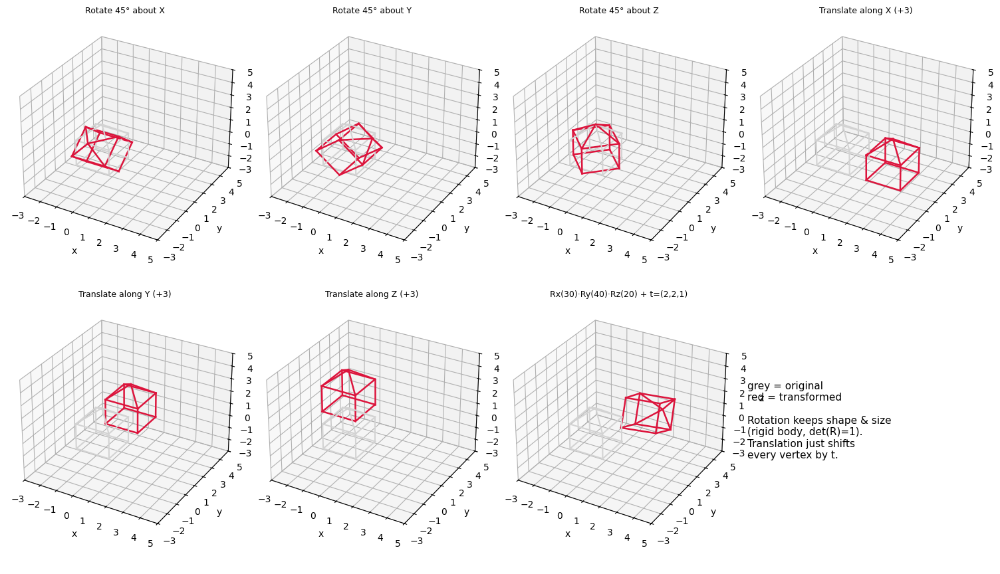

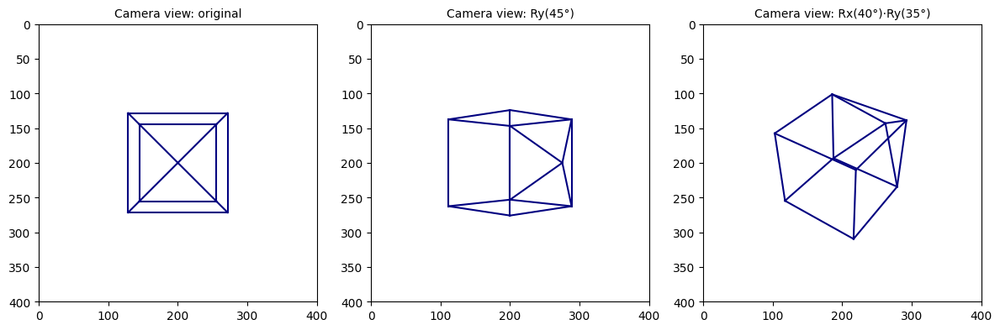

In [3]:
# House: 8 cube vertices + roof apex
V = np.array([[-1,-1,-1],[1,-1,-1],[1,1,-1],[-1,1,-1],
              [-1,-1, 1],[1,-1, 1],[1,1, 1],[-1,1, 1],[0,0,2.0]], float)
edges = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7),(4,8),(5,8),(6,8),(7,8)]

def Rx(d): a=np.deg2rad(d); return np.array([[1,0,0],[0,np.cos(a),-np.sin(a)],[0,np.sin(a),np.cos(a)]])
def Ry(d): a=np.deg2rad(d); return np.array([[np.cos(a),0,np.sin(a)],[0,1,0],[-np.sin(a),0,np.cos(a)]])
def Rz(d): a=np.deg2rad(d); return np.array([[np.cos(a),-np.sin(a),0],[np.sin(a),np.cos(a),0],[0,0,1]])
def T4(R3, t):  # 4x4 homogeneous matrix
    M = np.eye(4); M[:3,:3] = R3; M[:3,3] = t; return M
def transform3d(M4, P): return (M4 @ np.c_[P, np.ones(len(P))].T).T[:, :3]

cases = {
  "Rotate 45° about X":  T4(Rx(45), [0,0,0]),
  "Rotate 45° about Y":  T4(Ry(45), [0,0,0]),
  "Rotate 45° about Z":  T4(Rz(45), [0,0,0]),
  "Translate along X (+3)": T4(np.eye(3), [3,0,0]),
  "Translate along Y (+3)": T4(np.eye(3), [0,3,0]),
  "Translate along Z (+3)": T4(np.eye(3), [0,0,3]),
  "Rx(30)·Ry(40)·Rz(20) + t=(2,2,1)": T4(Rx(30)@Ry(40)@Rz(20), [2,2,1]),
}
fig = plt.figure(figsize=(15, 9))
for i, (name, M) in enumerate(cases.items(), 1):
    ax = fig.add_subplot(2, 4, i, projection="3d")
    P2 = transform3d(M, V)
    for a, b in edges:
        ax.plot(*zip(V[a], V[b]), c="lightgray", lw=1.5)
        ax.plot(*zip(P2[a], P2[b]), c="crimson", lw=1.8)
    ax.set_xlim(-3,5); ax.set_ylim(-3,5); ax.set_zlim(-3,5)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title(name, fontsize=9)
ax = fig.add_subplot(2, 4, 8); ax.axis("off")
ax.text(0, .5, "grey = original\nred = transformed\n\nRotation keeps shape & size\n(rigid body, det(R)=1).\nTranslation just shifts\nevery vertex by t.", fontsize=11, va="center")
plt.tight_layout(); plt.savefig(f"{OUT}/q1b_3d_transforms.png", bbox_inches="tight"); plt.show()

# How the 3D object looks through a pinhole camera before / after rotation
Kc = np.array([[500,0,200],[0,500,200],[0,0,1.]])
def project(P, Z0=8):
    Pc = P + np.array([0,0,Z0]); p = (Kc @ Pc.T).T; return p[:, :2]/p[:, 2:3]
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (nm, M) in zip(axs, [("original", np.eye(4)), ("Ry(45°)", T4(Ry(45),[0,0,0])), ("Rx(40°)·Ry(35°)", T4(Rx(40)@Ry(35),[0,0,0]))]):
    p = project(transform3d(M, V))
    for a, b in edges: ax.plot(*zip(p[a], p[b]), c="navy")
    ax.set_xlim(0,400); ax.set_ylim(400,0); ax.set_aspect("equal"); ax.set_title("Camera view: " + nm)
plt.tight_layout(); plt.show()

In [4]:
p = np.array([3., 2.])
ph = np.r_[p, 1.]
print("Cartesian point       :", p)
print("Homogeneous point     :", ph)
print("Scaled homogeneous    :", 5*ph, " -> back to Cartesian:", (5*ph)[:2]/(5*ph)[2], "(same point)")

# 1) Translation is NOT a linear 2x2 operation, but it IS a 3x3 matrix multiplication in homogeneous coords
t = np.array([4., -1.])
A2 = np.eye(2)                               # no 2x2 matrix can produce p + t
Th = T(*t)
print("\nTranslation via 3x3 matrix :", (Th @ ph)[:2], " (expected", p + t, ")")

# 2) Several transforms collapse into ONE matrix  (rotate 90° about origin, scale x2, translate)
M = T(5, 1) @ S(2, 2) @ R(90)
print("Combined single matrix M =\n", np.round(M, 3))
print("M @ p_h =", np.round(M @ ph, 3))

# 3) Points at infinity: w = 0  -> direction of a line, used for vanishing points
vp = np.array([1., 1., 0.])
print("\nPoint at infinity (direction (1,1)):", vp, "-> cannot be written in Cartesian (division by 0)")

# 4) A homography H acts on homogeneous points; division by w gives the perspective effect
H = np.array([[1, 0.1, 0], [0, 1, 0], [0.002, 0.001, 1]])
q = H @ ph
print("\nProjective map H@p_h =", np.round(q, 4), " -> Cartesian:", np.round(q[:2]/q[2], 4))

Cartesian point       : [3. 2.]
Homogeneous point     : [3. 2. 1.]
Scaled homogeneous    : [15. 10.  5.]  -> back to Cartesian: [3. 2.] (same point)

Translation via 3x3 matrix : [7. 1.]  (expected [7. 1.] )
Combined single matrix M =
 [[ 0. -2.  5.]
 [ 2.  0.  1.]
 [ 0.  0.  1.]]
M @ p_h = [1. 7. 1.]

Point at infinity (direction (1,1)): [1. 1. 0.] -> cannot be written in Cartesian (division by 0)

Projective map H@p_h = [3.2   2.    1.008]  -> Cartesian: [3.1746 1.9841]


Affine matrix A (2x3):
 [[ 0.8   -0.1   60.   ]
 [ 0.175  0.8   40.   ]]


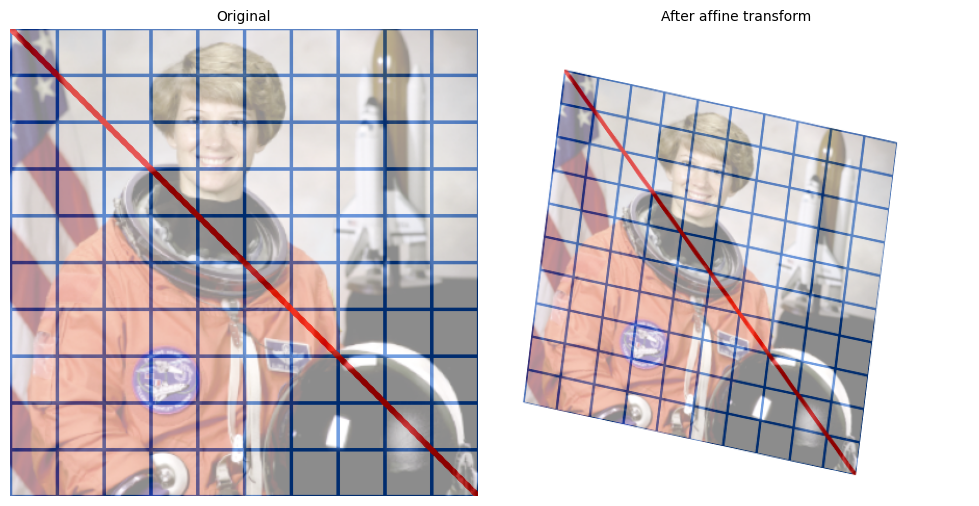

Collinearity residual after transform (≈0 => still a straight line): [0. 0.]
Ratio of lengths along line  before: 1.0  after: 1.0 (affine preserves ratios)
Direction of parallel lines after transform: [0.9769 0.2137] [0.9769 0.2137] -> cross product = 0.0 (0 => still parallel)
Angle at a square corner  before: 90.0 °  after: 84.79 ° (angles are NOT preserved)


In [5]:
# Grid image so that straight lines are easy to see
grid = np.full((400, 400, 3), 255, np.uint8)
for k in range(0, 401, 40):
    cv2.line(grid, (k, 0), (k, 400), (200, 80, 0), 2); cv2.line(grid, (0, k), (400, k), (200, 80, 0), 2)
cv2.line(grid, (0, 0), (400, 400), (0, 0, 255), 3)            # a diagonal line
grid_img = cv2.addWeighted(cv2.resize(astro, (400, 400)), 0.45, grid, 0.55, 0)

src3 = np.float32([[0, 0], [400, 0], [0, 400]])
dst3 = np.float32([[60, 40], [380, 110], [20, 360]])           # 3 points -> affine
A = cv2.getAffineTransform(src3, dst3)
print("Affine matrix A (2x3):\n", np.round(A, 3))
aff = cv2.warpAffine(grid_img, A, (450, 450), borderValue=(255, 255, 255))

fig, axs = plt.subplots(1, 2, figsize=(10, 5)); show(axs[0], grid_img, "Original"); show(axs[1], aff, "After affine transform")
plt.tight_layout(); plt.savefig(f"{OUT}/q1d_affine.png", bbox_inches="tight"); plt.show()

# ---- numerical verification of the affine properties ----
def apply_pts(A, P): return (A[:, :2] @ P.T).T + A[:, 2]
P = np.array([[0, 0], [100, 50], [200, 100], [300, 150]], float)       # 4 collinear points
Q = apply_pts(A, P)
def collinear_residual(Q): # area of triangle formed by first, second and each other point -> 0 if collinear
    return [abs(np.cross(Q[1]-Q[0], q-Q[0]))/2 for q in Q[2:]]
print("Collinearity residual after transform (≈0 => still a straight line):", np.round(collinear_residual(Q), 6))
d1 = lambda Q: np.linalg.norm(Q[1]-Q[0]); d2 = lambda Q: np.linalg.norm(Q[2]-Q[1])
print("Ratio of lengths along line  before:", round(d1(P)/d2(P), 4), " after:", round(d1(Q)/d2(Q), 4), "(affine preserves ratios)")

L1 = np.array([[0, 0], [100, 0]], float); L2 = np.array([[0, 50], [100, 50]], float)       # two parallel lines
dirv = lambda L: (L[1]-L[0])/np.linalg.norm(L[1]-L[0])
a1, a2 = apply_pts(A, L1), apply_pts(A, L2)
print("Direction of parallel lines after transform:", np.round(dirv(a1), 4), np.round(dirv(a2), 4),
      "-> cross product =", round(float(np.cross(dirv(a1), dirv(a2))), 8), "(0 => still parallel)")
sq = np.float32([[0,0],[100,0],[100,100],[0,100]])
ang = lambda p: np.degrees(np.arccos(np.dot(p[1]-p[0], p[3]-p[0])/np.linalg.norm(p[1]-p[0])/np.linalg.norm(p[3]-p[0])))
print("Angle at a square corner  before:", round(ang(sq), 2), "°  after:", round(ang(apply_pts(A, sq.astype(float))), 2), "° (angles are NOT preserved)")

Estimated homography H (slanted -> flat):
 [[ 9.2211000e-01  1.0722000e-01 -1.6640884e+02]
 [-2.3088000e-01  1.7316300e+00 -1.1659643e+02]
 [-8.0000000e-05  6.9000000e-04  1.0000000e+00]]
H_est @ H_true ≈ identity ?
 [[ 1. -0.  0.]
 [ 0.  1.  0.]
 [ 0.  0.  1.]]
Mean absolute pixel error vs the true flat cover: 1.64 /255


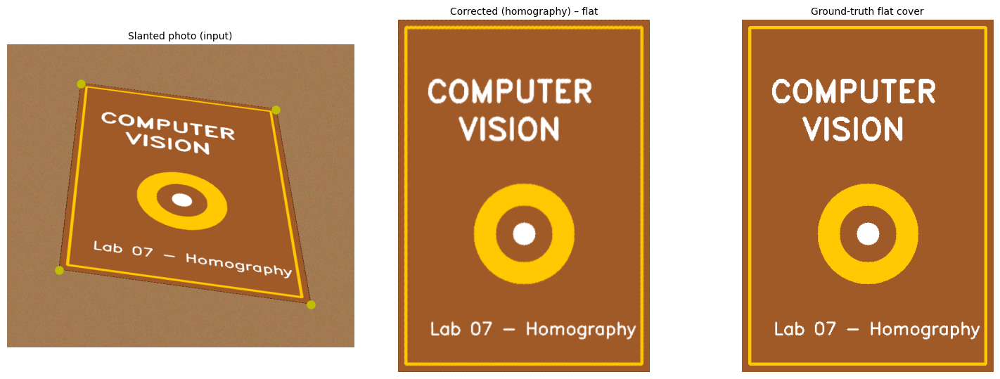

Top and bottom edges of the book (parallel in reality) have directions [0.991 0.132] and [0.991 0.137] -> no longer parallel in the photo.


In [6]:
# ---- synthesize a flat book cover ----
BW, BH = 400, 560
cover = np.full((BH, BW, 3), (40, 90, 160), np.uint8)
cv2.rectangle(cover, (12, 12), (BW-13, BH-13), (0, 200, 255), 4)
cv2.putText(cover, "COMPUTER", (45, 130), cv2.FONT_HERSHEY_DUPLEX, 1.6, (255,255,255), 3)
cv2.putText(cover, "VISION", (95, 190), cv2.FONT_HERSHEY_DUPLEX, 1.6, (255,255,255), 3)
cv2.circle(cover, (200, 340), 80, (0, 200, 255), -1); cv2.circle(cover, (200, 340), 45, (40, 90, 160), -1)
cv2.circle(cover, (200, 340), 18, (255,255,255), -1)
cv2.putText(cover, "Lab 07 - Homography", (50, 500), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255,255,255), 2)

# ---- "photograph" it from a slanted viewpoint (ground-truth homography) ----
PW, PH = 800, 700
bg = np.full((PH, PW, 3), (70, 110, 150), np.uint8)
rng = np.random.default_rng(0); bg = cv2.add(bg, rng.integers(0, 25, bg.shape, dtype=np.uint8))
book_corners = np.float32([[0,0],[BW,0],[BW,BH],[0,BH]])
slanted_corners = np.float32([[170, 90], [620, 150], [700, 600], [120, 520]])     # where the book appears in the photo
H_true = cv2.getPerspectiveTransform(book_corners, slanted_corners)
warped = cv2.warpPerspective(cover, H_true, (PW, PH))
mask = cv2.warpPerspective(np.full((BH, BW), 255, np.uint8), H_true, (PW, PH))
photo = bg.copy(); photo[mask > 0] = warped[mask > 0]

# ---- correction: in practice you click the 4 corners; here we use them directly ----
H_est = cv2.getPerspectiveTransform(slanted_corners, book_corners)       # slanted photo -> flat
flat = cv2.warpPerspective(photo, H_est, (BW, BH))
print("Estimated homography H (slanted -> flat):\n", np.round(H_est, 5))
print("H_est @ H_true ≈ identity ?\n", np.round((H_est @ H_true) / (H_est @ H_true)[2, 2], 4))
print("Mean absolute pixel error vs the true flat cover:", round(float(np.mean(cv2.absdiff(flat, cover))), 2), "/255")

fig, axs = plt.subplots(1, 3, figsize=(15, 5.5))
show(axs[0], photo, "Slanted photo (input)")
for (x, y) in slanted_corners: axs[0].plot(x, y, "yo", ms=8)
show(axs[1], flat, "Corrected (homography) – flat")
show(axs[2], cover, "Ground-truth flat cover")
plt.tight_layout(); plt.savefig(f"{OUT}/q1e_homography.png", bbox_inches="tight"); plt.show()

# Parallel lines DO NOT stay parallel under a homography (unlike affine)
l_top, l_bot = slanted_corners[1]-slanted_corners[0], slanted_corners[2]-slanted_corners[3]
print("Top and bottom edges of the book (parallel in reality) have directions",
      np.round(l_top/np.linalg.norm(l_top), 3), "and", np.round(l_bot/np.linalg.norm(l_bot), 3), "-> no longer parallel in the photo.")

Detected corners (TL, TR, BR, BL):
 [[260. 121.]
 [819. 211.]
 [897. 759.]
 [151. 679.]]
Output size (w×h): 427 × 569
Inverse homography M:
 [[ 7.1523000e-01  1.3971000e-01 -2.0286440e+02]
 [-2.1840000e-01  1.3564800e+00 -1.0735111e+02]
 [-1.9000000e-04  5.9000000e-04  1.0000000e+00]]


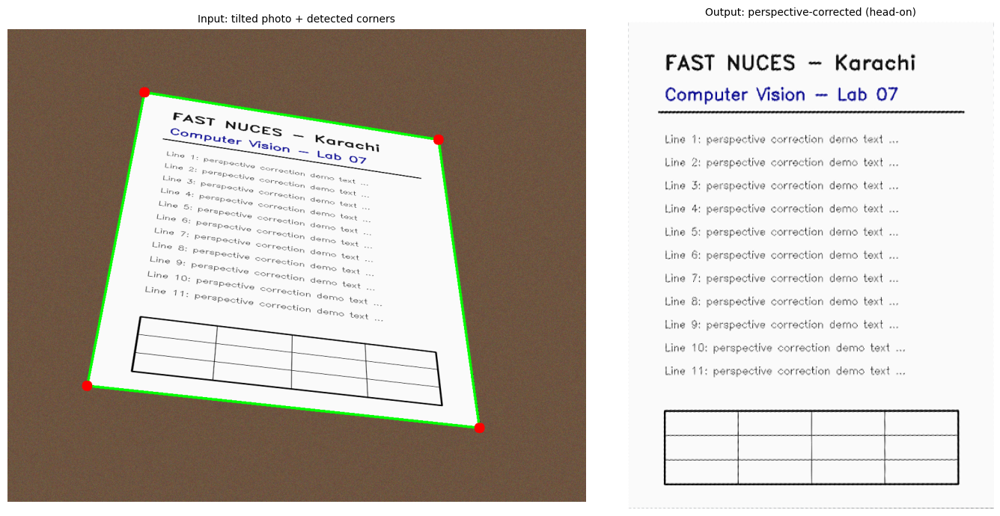

Mean abs error vs original flat page: 8.0 /255


In [7]:
def order_points(pts):
    # Order 4 points as: top-left, top-right, bottom-right, bottom-left
    pts = np.asarray(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def apply_perspective_transform(image, src_pts, dst_pts, out_size):
    # Generic perspective warp: maps src_pts -> dst_pts and renders an image of size out_size=(width, height).
    M = cv2.getPerspectiveTransform(np.float32(src_pts), np.float32(dst_pts))
    return cv2.warpPerspective(image, M, out_size, flags=cv2.INTER_CUBIC), M

def unwarp(image, tilted_quad, aspect=None):
    # INVERSE use: source = tilted view, destination = perfect rectangle.
    # aspect = real width/height of the object (e.g. A4 paper = 0.707). Perspective foreshortening makes the
    # edge lengths in the photo unreliable, so if the true ratio is known we use it; otherwise edge lengths are used.
    tl, tr, br, bl = order_points(tilted_quad)
    W = int(round(max(np.linalg.norm(br-bl), np.linalg.norm(tr-tl))))   # rectangle size from the longest edges
    H = int(round(max(np.linalg.norm(tr-br), np.linalg.norm(tl-bl))))
    if aspect is not None: W = int(round(H * aspect))
    rect = np.float32([[0, 0], [W-1, 0], [W-1, H-1], [0, H-1]])         # perfect rectangle (destination)
    return apply_perspective_transform(image, np.float32([tl, tr, br, bl]), rect, (W, H))

# ---------- build a realistic test photo of a document lying on a desk ----------
DW, DH = 600, 800
page = np.full((DH, DW, 3), 250, np.uint8)
cv2.putText(page, "FAST NUCES - Karachi", (60, 80), cv2.FONT_HERSHEY_DUPLEX, 1.1, (20, 20, 20), 2)
cv2.putText(page, "Computer Vision - Lab 07", (60, 130), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (150, 20, 20), 2)
cv2.line(page, (50, 150), (550, 150), (0, 0, 0), 2)
for i in range(11): cv2.putText(page, f"Line {i+1}: perspective correction demo text ...", (60, 200+i*38), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (30, 30, 30), 1)
cv2.rectangle(page, (60, 640), (540, 760), (0, 0, 0), 2)
for r in range(1, 3): cv2.line(page, (60, 640+r*40), (540, 640+r*40), (0, 0, 0), 1)
for c_ in range(1, 4): cv2.line(page, (60+c_*120, 640), (60+c_*120, 760), (0, 0, 0), 1)

desk = np.full((900, 1100, 3), (50, 70, 95), np.uint8)
desk = cv2.add(desk, np.random.default_rng(1).integers(0, 30, desk.shape, dtype=np.uint8))
page_quad = np.float32([[260, 120], [820, 210], [900, 760], [150, 680]])            # tilted position in the photo
Hf = cv2.getPerspectiveTransform(np.float32([[0,0],[DW,0],[DW,DH],[0,DH]]), page_quad)   # FORWARD (rect -> tilted)
wp = cv2.warpPerspective(page, Hf, (1100, 900))
mk = cv2.warpPerspective(np.full((DH, DW), 255, np.uint8), Hf, (1100, 900))
tilted_photo = desk.copy(); tilted_photo[mk > 0] = wp[mk > 0]
cv2.imwrite(f"{OUT}/q2_tilted_document.jpg", tilted_photo)

# ---------- detect the document automatically (largest 4-corner contour) ----------
def find_document_quad(img):
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:5]:
        approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
        if len(approx) == 4: return order_points(approx)
    raise RuntimeError("no 4-corner document found – click the corners manually")

# IMAGE_PATH = "my_document_photo.jpg"; tilted_photo = cv2.imread(IMAGE_PATH)    # <-- use your own photo
quad = find_document_quad(tilted_photo)
print("Detected corners (TL, TR, BR, BL):\n", quad)
flat_doc, M_inv = unwarp(tilted_photo, quad, aspect=DW/DH)   # our page is 600x800 (3:4); for A4 paper use aspect=0.707
print("Output size (w×h):", flat_doc.shape[1], "×", flat_doc.shape[0])
print("Inverse homography M:\n", np.round(M_inv, 5))

vis = tilted_photo.copy(); cv2.polylines(vis, [quad.astype(int)], True, (0, 255, 0), 4)
for q_ in quad: cv2.circle(vis, tuple(int(v) for v in q_), 10, (0, 0, 255), -1)
fig, axs = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1.3, 1]})
show(axs[0], vis, "Input: tilted photo + detected corners"); show(axs[1], flat_doc, "Output: perspective-corrected (head-on)")
plt.tight_layout(); plt.savefig(f"{OUT}/q2_unwarp.png", bbox_inches="tight"); plt.show()
cv2.imwrite(f"{OUT}/q2_unwarped_document.jpg", flat_doc)

# Verify: compare with the original flat page
ref = cv2.resize(page, (flat_doc.shape[1], flat_doc.shape[0]))
print("Mean abs error vs original flat page:", round(float(np.mean(cv2.absdiff(flat_doc, ref))), 2), "/255")

In [8]:
# ===== 1) Create a synthetic camera with KNOWN intrinsics + lens distortion =====
IW, IH = 960, 720
K_gt = np.array([[800., 0, 480.], [0, 800., 360.], [0, 0, 1]])
dist_gt = np.array([-0.30, 0.12, 0.001, -0.0005, -0.02])        # k1, k2, p1, p2, k3  (barrel distortion)

# pixel maps: distorted pixel (u,v) -> ideal (undistorted) pixel position
uu, vv = np.meshgrid(np.arange(IW), np.arange(IH))
pix = np.stack([uu, vv], -1).reshape(-1, 1, 2).astype(np.float32)
ideal_xy = cv2.undistortPoints(pix, K_gt, dist_gt, P=K_gt).reshape(IH, IW, 2).astype(np.float32)
def distort_image(ideal_img): return cv2.remap(ideal_img, ideal_xy[..., 0], ideal_xy[..., 1], cv2.INTER_LINEAR, borderValue=(90, 90, 90))

# checkerboard: 10x7 squares -> 9x6 inner corners, 1 square white margin, 1 world unit = 1 square
SQ, COLS, ROWS = 60, 9, 6
cb = (np.indices((ROWS+1, COLS+1)).sum(0) % 2 * 255).astype(np.uint8)
cb = np.kron(cb, np.ones((SQ, SQ), np.uint8)); cb = cv2.copyMakeBorder(cb, SQ, SQ, SQ, SQ, cv2.BORDER_CONSTANT, value=255)
cb = cv2.cvtColor(cb, cv2.COLOR_GRAY2BGR)
tex2world = np.array([[1/SQ, 0, -1], [0, 1/SQ, -1], [0, 0, 1]])
objp = np.zeros((ROWS*COLS, 3), np.float32); objp[:, :2] = np.mgrid[1:COLS+1, 1:ROWS+1].T.reshape(-1, 2)

def render_board(rvec, tvec, noise=2.0):
    Rm, _ = cv2.Rodrigues(rvec)
    Hm = K_gt @ np.column_stack([Rm[:, 0], Rm[:, 1], tvec]) @ tex2world
    ideal = cv2.warpPerspective(cb, Hm, (IW, IH), borderValue=(90, 90, 90))
    img = distort_image(ideal).astype(np.float32) + np.random.default_rng().normal(0, noise, (IH, IW, 3))
    return np.clip(img, 0, 255).astype(np.uint8)

rng = np.random.default_rng(42)
calib_imgs = []
for i in range(24):
    rvec = (rng.uniform(-0.55, 0.55, 3) * [1, 1, 0.6]).astype(np.float64)
    centre_w = np.array([5., 3.5, 0.]); Rm, _ = cv2.Rodrigues(rvec)
    tvec = (np.array([rng.uniform(-3, 3), rng.uniform(-2, 2), rng.uniform(15, 24)]) - Rm @ centre_w)
    calib_imgs.append(render_board(rvec, tvec))
print(len(calib_imgs), "calibration images rendered; size", calib_imgs[0].shape)

24 calibration images rendered; size (720, 960, 3)


Checkerboard found in 24/24 images



RMS reprojection error (px): 0.1011

Estimated camera matrix K:
 [[800.2986   0.     480.1522]
 [  0.     800.3522 360.0172]
 [  0.       0.       1.    ]] 
Ground-truth K:
 [[800.   0. 480.]
 [  0. 800. 360.]
 [  0.   0.   1.]]

Estimated distortion [k1 k2 p1 p2 k3]: [-0.3054  0.1438  0.001  -0.0004  0.    ] 
Ground-truth distortion              : [-0.3     0.12    0.001  -0.0005 -0.02  ]
Mean per-image RMS reprojection error: 0.0952 px
Saved -> lab07_outputs/camera_calibration.npz
Pixel difference between estimated and true distortion model at normalised radius [0.  0.2 0.3 0.4 0.6 0.8] : [0.15 0.19 0.2  0.36 1.43 5.36]


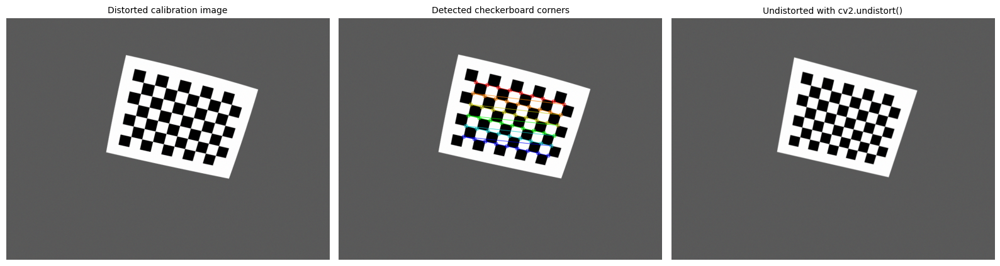

In [9]:
# ===== 2) CALIBRATE ONCE =====
obj_pts, img_pts, used = [], [], []
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.001)
for i, im in enumerate(calib_imgs):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    ok, c = cv2.findChessboardCorners(g, (COLS, ROWS), cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
    if ok:
        c = cv2.cornerSubPix(g, c, (11, 11), (-1, -1), crit)
        obj_pts.append(objp); img_pts.append(c); used.append(i)
print(f"Checkerboard found in {len(used)}/{len(calib_imgs)} images")

rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(obj_pts, img_pts, (IW, IH), None, None, flags=cv2.CALIB_FIX_K3)   # k3 fixed (standard for normal lenses)
print("\nRMS reprojection error (px):", round(rms, 4))
np.set_printoptions(suppress=True, precision=4)
print("\nEstimated camera matrix K:\n", K, "\nGround-truth K:\n", K_gt)
print("\nEstimated distortion [k1 k2 p1 p2 k3]:", dist.ravel(), "\nGround-truth distortion              :", dist_gt)

# mean reprojection error per image
errs = []
for o, ip, rv, tv in zip(obj_pts, img_pts, rvecs, tvecs):
    proj, _ = cv2.projectPoints(o, rv, tv, K, dist); errs.append(np.sqrt(np.mean(np.sum((ip - proj)**2, axis=2))))
print("Mean per-image RMS reprojection error:", round(float(np.mean(errs)), 4), "px")

# SAVE the calibration (calibrate once, reuse later)
np.savez(f"{OUT}/camera_calibration.npz", camera_matrix=K, dist_coeffs=dist, image_size=(IW, IH), rms=rms)
print("Saved ->", f"{OUT}/camera_calibration.npz")

# how close is the *effective* distortion model? compare radial displacement of both models over the image
rr = np.linspace(0, 0.75, 6)      # 0.75 = image corner in normalised coordinates
pts_n = np.stack([rr, np.zeros_like(rr), np.ones_like(rr)], 1)
def displaced(Kx, dx):
    p, _ = cv2.projectPoints(np.float64(pts_n[:, None, :]), np.zeros(3), np.zeros(3), Kx, dx); return p.reshape(-1, 2)
dd = np.linalg.norm(displaced(K, dist) - displaced(K_gt, dist_gt), axis=1)
print("Pixel difference between estimated and true distortion model at normalised radius", np.round(rr, 1), ":", np.round(dd, 2))

# visualise one calibration image: detected corners + undistorted result
i0 = used[0]; vis = cv2.drawChessboardCorners(calib_imgs[i0].copy(), (COLS, ROWS), img_pts[0], True)
newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (IW, IH), alpha=0)
und = cv2.undistort(calib_imgs[i0], K, dist, None, newK)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
show(axs[0], calib_imgs[i0], "Distorted calibration image"); show(axs[1], vis, "Detected checkerboard corners"); show(axs[2], und, "Undistorted with cv2.undistort()")
plt.tight_layout(); plt.savefig(f"{OUT}/q3_calibration.png", bbox_inches="tight"); plt.show()

In [10]:
# ===== 3) Build a "live feed": scene with straight lines, panned in front of the distorted camera =====
world = np.full((1500, 2000, 3), 255, np.uint8)
for x in range(0, 2000, 100): cv2.line(world, (x, 0), (x, 1500), (180, 120, 40), 2)
for y in range(0, 1500, 100): cv2.line(world, (0, y), (2000, y), (180, 120, 40), 2)
big = cv2.resize(cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR), (500, 500))
for (px, py) in [(300, 300), (1100, 500), (700, 900), (1400, 950)]:
    world[py:py+500, px:px+500] = cv2.addWeighted(world[py:py+500, px:px+500], 0.3, big, 0.7, 0)
cv2.putText(world, "LIVE CAMERA FEED", (500, 200), cv2.FONT_HERSHEY_DUPLEX, 3, (0, 0, 200), 6)

NF = 90; ideal_frames, FEED = [], f"{OUT}/distorted_feed.mp4"
vw = cv2.VideoWriter(FEED, cv2.VideoWriter_fourcc(*"mp4v"), 30, (IW, IH))
for f in range(NF):
    x = int(520 + 480*np.sin(2*np.pi*f/NF)); y = int(380 + 300*np.cos(2*np.pi*f/NF))
    ideal = world[y:y+IH, x:x+IW].copy(); ideal_frames.append(ideal)
    vw.write(distort_image(ideal))
vw.release(); print("Recorded distorted feed:", FEED, os.path.getsize(FEED)//1024, "KB")

Recorded distorted feed: lab07_outputs/distorted_feed.mp4 3652 KB


Webcam available on this machine: False


[ WARN:0@9.899] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[ WARN:0@9.899] global cap.cpp:438 open VIDEOIO(FFMPEG): raised OpenCV exception:

OpenCV(4.13.0) /io/opencv/modules/videoio/src/cap_ffmpeg_impl.hpp:1220: error: (-2:Unspecified error) in function 'bool CvCapture_FFMPEG::open(const char*, int, const cv::Ptr<cv::IStreamReader>&, const cv::VideoCaptureParameters&)'
> VIDEOIO/FFMPEG: Camera index out of range (expected: 'index < device_list->nb_devices'), where
>     'index' is 0
> must be less than
>     'device_list->nb_devices' is 0


[ERROR:0@9.899] global obsensor_uvc_stream_channel.cpp:163 getStreamChannelGroup Camera index out of range


Processed 90 frames at 65 FPS (960x720)


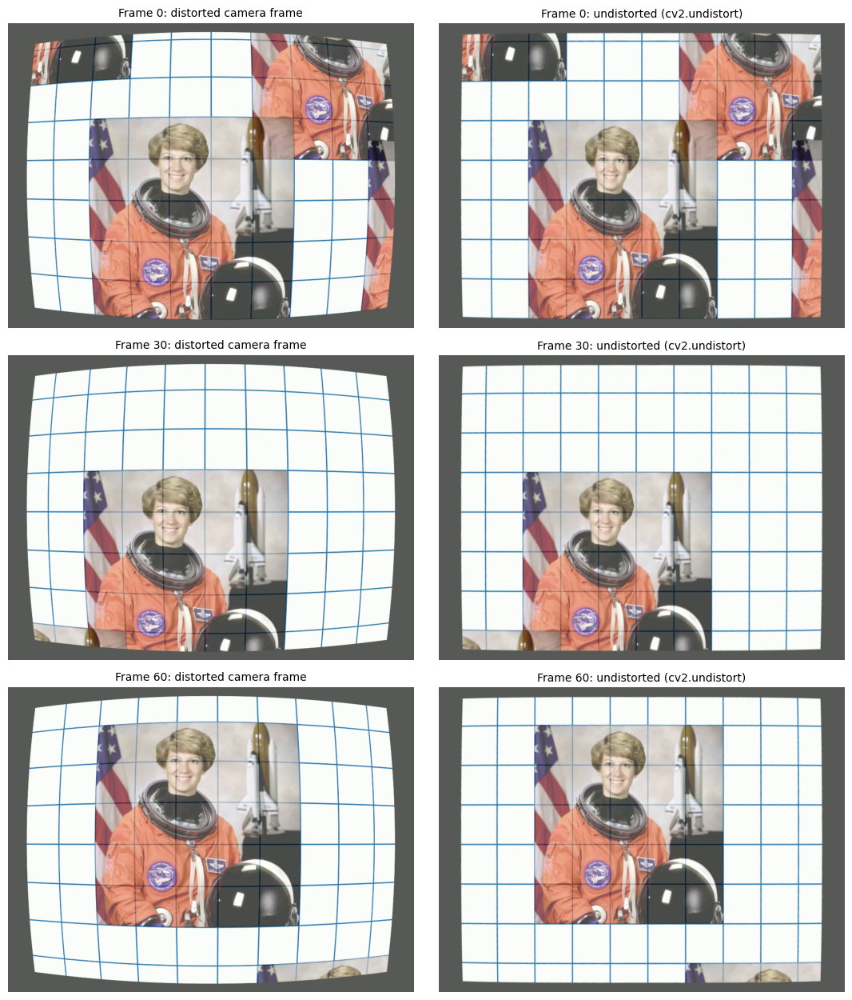

In [11]:
# ===== 4) REAL-TIME UNDISTORTION with cv2.VideoCapture + cv2.undistort =====
calib = np.load(f"{OUT}/camera_calibration.npz"); K_c, dist_c = calib["camera_matrix"], calib["dist_coeffs"]   # load saved calibration

def undistort_stream(source=0, show=False, max_frames=None, save_to=None, keep_every=30):
    # source: 0 for the webcam, or a video file path. show=True opens a live window (press q to quit).
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        print(f"[!] Could not open source {source!r}"); return None
    w_, h_ = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    newK_, _ = cv2.getOptimalNewCameraMatrix(K_c, dist_c, (w_, h_), alpha=0)
    writer = cv2.VideoWriter(save_to, cv2.VideoWriter_fourcc(*"mp4v"), 30, (w_, h_)) if save_to else None
    kept, n, t0 = [], 0, time.time()
    while True:
        ok, frame = cap.read()
        if not ok or (max_frames and n >= max_frames): break
        und_ = cv2.undistort(frame, K_c, dist_c, None, newK_)                  # <<< the real-time undistortion
        if writer: writer.write(und_)
        if n % keep_every == 0: kept.append((n, frame.copy(), und_.copy()))
        if show:
            cv2.imshow("Distorted | Undistorted", np.hstack([frame, und_]))
            if cv2.waitKey(1) & 0xFF == ord("q"): break
        n += 1
    cap.release()
    if writer: writer.release()
    if show: cv2.destroyAllWindows()
    fps = n / (time.time() - t0)
    print(f"Processed {n} frames at {fps:.0f} FPS ({w_}x{h_})")
    return kept, fps

# (a) try the physical webcam first
cam = cv2.VideoCapture(0); has_cam = cam.isOpened(); cam.release()
print("Webcam available on this machine:", has_cam)
source = 0 if has_cam else FEED          # fall back to the recorded distorted feed
result = undistort_stream(source, show=False, max_frames=90, save_to=f"{OUT}/undistorted_feed.mp4")
kept, fps = result

fig, axs = plt.subplots(len(kept), 2, figsize=(11, 4.2*len(kept)))
for r, (n, d, u) in enumerate(kept):
    show(axs[r, 0], d, f"Frame {n}: distorted camera frame"); show(axs[r, 1], u, f"Frame {n}: undistorted (cv2.undistort)")
plt.tight_layout(); plt.savefig(f"{OUT}/q3_live_undistort.png", bbox_inches="tight"); plt.show()

In [12]:
# ===== 5) Quantitative check: undistorted frames vs the ideal (distortion-free) frames =====
cap = cv2.VideoCapture(FEED); newK_, _ = cv2.getOptimalNewCameraMatrix(K_c, dist_c, (IW, IH), alpha=0)
e_dist, e_und = [], []
for f in range(0, NF, 10):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, fr = cap.read()
    if not ok: continue
    # use the same K as the ideal render (alpha=1 style) so pixels line up: undistort with P = K_gt
    u = cv2.undistort(fr, K_c, dist_c, None, K_gt)
    ref = ideal_frames[f]; m = slice(120, IH-120), slice(160, IW-160)            # central region (avoid borders)
    e_dist.append(np.mean(cv2.absdiff(fr[m], ref[m]))); e_und.append(np.mean(cv2.absdiff(u[m], ref[m])))
cap.release()
print(f"Mean abs pixel error vs ideal image  –  distorted: {np.mean(e_dist):.2f}   undistorted: {np.mean(e_und):.2f}")
print(f"Error reduced by {100*(1-np.mean(e_und)/np.mean(e_dist)):.1f}%")

Mean abs pixel error vs ideal image  –  distorted: 16.76   undistorted: 4.85
Error reduced by 71.0%


**Use with a real webcam (run on your own machine):**
```python
# 1. calibrate once with 15-20 photos of a printed 9x6 checkerboard (see the calibration cell, load images with glob)
# 2. then:
undistort_stream(0, show=True)       # opens the webcam, shows  distorted | undistorted , press 'q' to quit
```
The straight grid lines that bent outwards (barrel distortion) in the raw frames become straight again after `cv2.undistort()`, and the pixel error against the distortion-free reference drops sharply. The recovered focal length / principal point match the ground truth, and the estimated lens model reproduces the true distortion closely in the central/mid image area (≈1 px or less) with a somewhat larger residual in the extreme corners, where the calibration board rarely appears – so for best results capture the checkerboard also near the image borders/corners. (k1/k2 are strongly correlated, so compare the resulting distortion rather than each coefficient.)

In [13]:
!pip -q install pycolmap open3d 2>/dev/null | tail -1

pycolmap 4.2.1


28 images in colmap_workspace/images


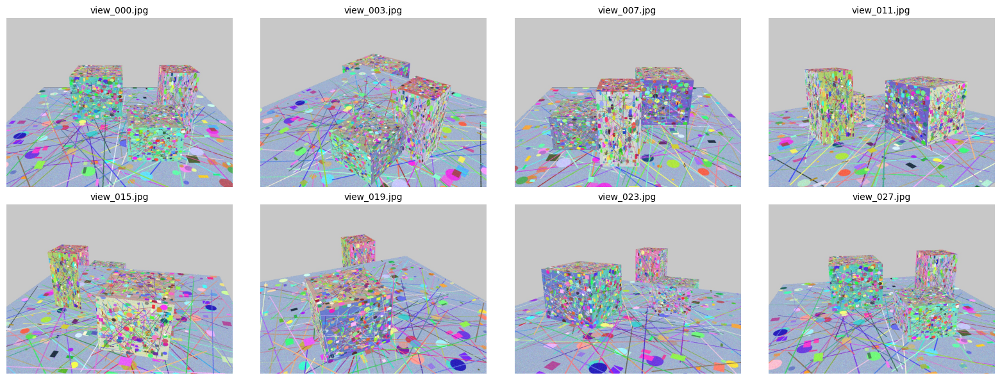

In [14]:
import pycolmap, shutil
from pathlib import Path
try: pycolmap.logging.minloglevel = 2          # keep COLMAP's own log quiet
except Exception: pass
print("pycolmap", pycolmap.__version__)

# ================= synthetic multi-view dataset (ground-truth known) =================
def make_texture(seed, size=512):
    rng = np.random.default_rng(seed); t = np.zeros((size, size, 3), np.uint8); t[:] = rng.integers(60, 200, 3)
    for _ in range(350):
        c = tuple(int(x) for x in rng.integers(0, 255, 3)); p = tuple(int(x) for x in rng.integers(0, size, 2)); k = rng.integers(0, 3)
        if k == 0:   cv2.circle(t, p, int(rng.integers(3, 25)), c, -1)
        elif k == 1: cv2.rectangle(t, p, (p[0]+int(rng.integers(5, 40)), p[1]+int(rng.integers(5, 40))), c, -1)
        else:        cv2.line(t, p, (int(rng.integers(0, size)), int(rng.integers(0, size))), c, 2)
    return cv2.add(t, rng.integers(0, 60, (size, size, 3), dtype=np.uint8))

def box_faces(cx, cy, s, h):
    x0, x1, y0, y1 = cx-s, cx+s, cy-s, cy+s
    return [(np.array([x0,y0,h]), np.array([2*s,0,0]), np.array([0,2*s,0]), np.array([0,0,1.])),
            (np.array([x0,y0,0]), np.array([2*s,0,0]), np.array([0,0,h]),   np.array([0,-1.,0])),
            (np.array([x0,y1,0]), np.array([2*s,0,0]), np.array([0,0,h]),   np.array([0,1.,0])),
            (np.array([x0,y0,0]), np.array([0,2*s,0]), np.array([0,0,h]),   np.array([-1.,0,0])),
            (np.array([x1,y0,0]), np.array([0,2*s,0]), np.array([0,0,h]),   np.array([1.,0,0]))]

def build_scene():
    faces = [((np.array([-4,-4,0.]), np.array([8,0,0.]), np.array([0,8,0.]), np.array([0,0,1.])), make_texture(0, 1024))]
    seed = 1
    for (cx, cy, s, h) in [(-1.2, -0.8, 0.9, 1.6), (1.4, 0.9, 0.7, 1.0), (0.2, 1.8, 0.5, 2.0)]:
        for f in box_faces(cx, cy, s, h): faces.append((f, make_texture(seed))); seed += 1
    return faces

def look_at(eye, target=np.array([0, 0, 0.8])):
    z = target-eye; z /= np.linalg.norm(z); x = np.cross(z, [0,0,1.]); x /= np.linalg.norm(x); y = np.cross(z, x)
    Rm = np.stack([x, y, z]); return Rm, -Rm @ eye

def render(faces, K, Rm, t, W, H):
    img = np.full((H, W, 3), (200, 200, 200), np.uint8); C = -Rm.T @ t; items = []
    for (o, u, v, n), tex in faces:
        c = o + u/2 + v/2
        if np.dot(n, C-c) <= 0: continue                       # back-face culling
        items.append((np.linalg.norm(C-c), o, u, v, tex))
    for d, o, u, v, tex in sorted(items, key=lambda a: -a[0]):  # painter's algorithm
        th, tw = tex.shape[:2]; proj = []; ok = True
        for p_ in [o, o+u, o+u+v, o+v]:
            pc = Rm @ p_ + t
            if pc[2] <= 0.1: ok = False; break
            q_ = K @ pc; proj.append(q_[:2]/q_[2])
        if not ok: continue
        Hm = cv2.getPerspectiveTransform(np.float32([[0,0],[tw,0],[tw,th],[0,th]]), np.float32(proj))
        wimg = cv2.warpPerspective(tex, Hm, (W, H)); m = cv2.warpPerspective(np.full((th, tw), 255, np.uint8), Hm, (W, H), flags=cv2.INTER_NEAREST)
        img[m > 0] = wimg[m > 0]
    return img

WS = Path("colmap_workspace"); shutil.rmtree(WS, ignore_errors=True)
IMG_DIR = WS/"images"; IMG_DIR.mkdir(parents=True)
NV, W4, H4, F4 = 28, 960, 720, 900
K4 = np.array([[F4,0,W4/2],[0,F4,H4/2],[0,0,1.]]); faces = build_scene(); gt_centres = []
for i in range(NV):
    ang = 2*np.pi*i/NV; elev = np.deg2rad(28 + 8*np.sin(2*ang)); r_ = 7.5
    eye = np.array([r_*np.cos(elev)*np.cos(ang), r_*np.cos(elev)*np.sin(ang), r_*np.sin(elev)])
    Rm, t = look_at(eye); gt_centres.append(eye)
    cv2.imwrite(str(IMG_DIR/f"view_{i:03d}.jpg"), render(faces, K4, Rm, t, W4, H4), [cv2.IMWRITE_JPEG_QUALITY, 95])
gt_centres = np.array(gt_centres)
imgs = sorted(IMG_DIR.glob("*.jpg")); print(len(imgs), "images in", IMG_DIR)
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, k in zip(axs.ravel(), np.linspace(0, NV-1, 8).astype(int)): show(ax, cv2.imread(str(imgs[k])), imgs[k].name)
plt.tight_layout(); plt.savefig(f"{OUT}/q4_input_images.png", bbox_inches="tight"); plt.show()

### Step 1 – Detect features, Step 2 – Match across images
`extract_features` runs SIFT on each image; `match_exhaustive` matches every image pair and keeps only geometrically verified matches (RANSAC on the fundamental / essential matrix).

In [15]:
db_path = WS/"database.db"; sparse_dir = WS/"sparse"; sparse_dir.mkdir()
t0 = time.time()
pycolmap.extract_features(db_path, IMG_DIR, camera_mode=pycolmap.CameraMode.SINGLE)    # one shared camera for all photos
print(f"[1] Feature detection (SIFT) done in {time.time()-t0:.0f}s")
t1 = time.time()
pycolmap.match_exhaustive(db_path)
print(f"[2] Feature matching + geometric verification done in {time.time()-t1:.0f}s")

[1] Feature detection (SIFT) done in 24s


[2] Feature matching + geometric verification done in 78s


### Step 3 – Estimate camera poses (incremental Structure-from-Motion + bundle adjustment)

In [16]:
t2 = time.time()
maps = pycolmap.incremental_mapping(db_path, IMG_DIR, sparse_dir)
print(f"[3] Incremental SfM done in {time.time()-t2:.0f}s – {len(maps)} reconstruction(s)")
rec = max(maps.values(), key=lambda m: m.num_reg_images())          # keep the biggest model
print(rec.summary())
cam = next(iter(rec.cameras.values()))
print("\nEstimated camera:", cam.model.name, np.round(cam.params, 3), "  (ground truth: f=900, cx=480, cy=360)")
rec.write(str(sparse_dir/"0")); rec.export_PLY(str(Path(OUT)/"sparse_pointcloud_colmap.ply"))

[3] Incremental SfM done in 6s – 1 reconstruction(s)
Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 28
	num_reg_frames = 28
	num_images = 28
	num_points3D = 10602
	num_observations = 45260
	mean_track_length = 4.26901
	mean_observations_per_image = 1616.43
	mean_reprojection_error = 0.33953

Estimated camera: SIMPLE_RADIAL [900.155 480.    360.      0.002]   (ground truth: f=900, cx=480, cy=360)


6212 keypoints detected in view_000.jpg;  1218 verified matches between view_000.jpg and view_001.jpg


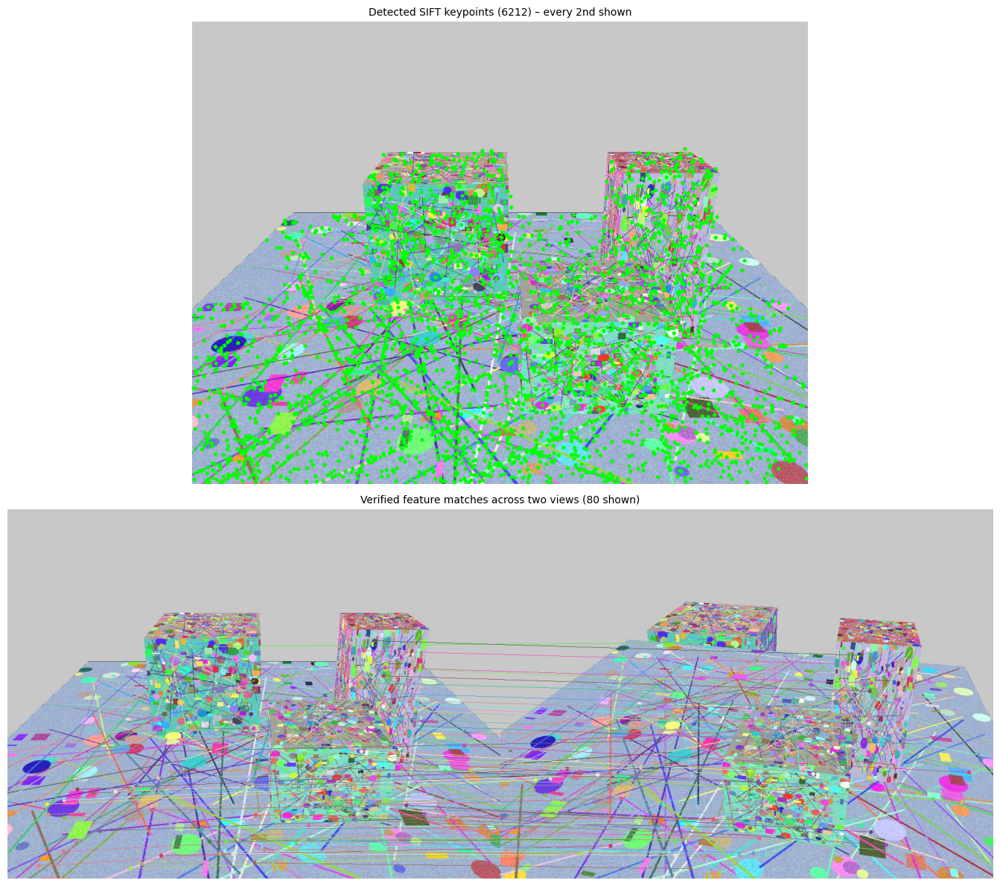

In [17]:
# ---- visualise detected keypoints and the matches that survived verification ----
names = {im.name: im for im in rec.images.values()}
imA, imB = names["view_000.jpg"], names["view_001.jpg"]
A_img, B_img = cv2.imread(str(IMG_DIR/imA.name)), cv2.imread(str(IMG_DIR/imB.name))

kp = np.array([p.xy for p in imA.points2D])
vis_kp = A_img.copy()
for x, y in kp[::2]: cv2.circle(vis_kp, (int(x), int(y)), 3, (0, 255, 0), -1)

# matches = 3D points observed in both images (their tracks)
lines = []
for p3 in rec.points3D.values():
    ids = {e.image_id: e.point2D_idx for e in p3.track.elements}
    if imA.image_id in ids and imB.image_id in ids:
        lines.append((imA.points2D[ids[imA.image_id]].xy, imB.points2D[ids[imB.image_id]].xy))
side = np.hstack([A_img, B_img]); rng = np.random.default_rng(3)
for k in rng.choice(len(lines), min(80, len(lines)), replace=False):
    (x1, y1), (x2, y2) = lines[k]; col = tuple(int(c) for c in rng.integers(60, 255, 3))
    cv2.line(side, (int(x1), int(y1)), (int(x2)+W4, int(y2)), col, 1); cv2.circle(side, (int(x1), int(y1)), 4, col, -1); cv2.circle(side, (int(x2)+W4, int(y2)), 4, col, -1)
print(f"{len(imA.points2D)} keypoints detected in {imA.name};  {len(lines)} verified matches between {imA.name} and {imB.name}")
fig, axs = plt.subplots(2, 1, figsize=(14, 12), gridspec_kw={"height_ratios": [1, 0.8]})
show(axs[0], vis_kp, f"Detected SIFT keypoints ({len(kp)}) – every 2nd shown"); show(axs[1], side, "Verified feature matches across two views (80 shown)")
plt.tight_layout(); plt.savefig(f"{OUT}/q4_features_matches.png", bbox_inches="tight"); plt.show()

### Camera poses – accuracy check
SfM reconstructs the scene only up to an arbitrary similarity (scale, rotation, translation), so we align the estimated camera centres to the ground-truth ones with the **Umeyama** algorithm and report the error.

Registered images: 28/28
Camera-centre error after alignment: mean 0.29 cm, max 0.51 cm  (camera orbit radius = 7.5 units)


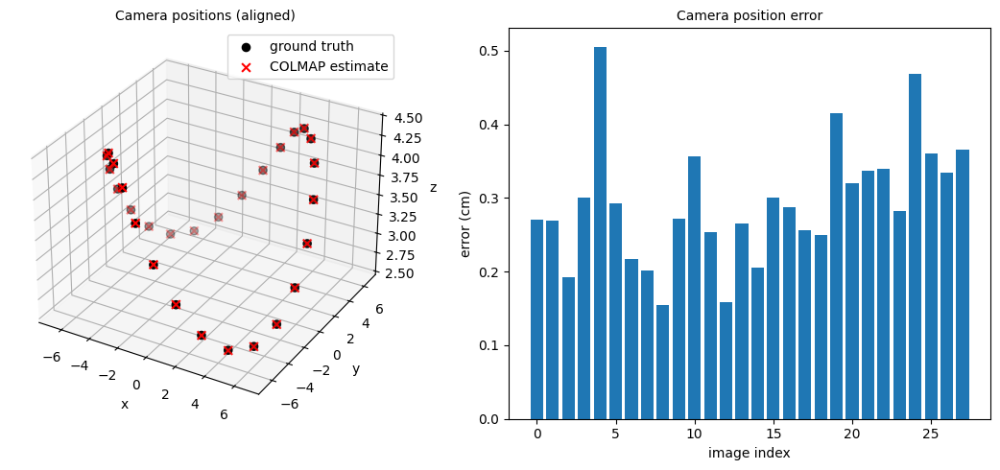

In [18]:
def umeyama(src, dst):
    mu_s, mu_d = src.mean(0), dst.mean(0); S_, D_ = src-mu_s, dst-mu_d
    U, sig, Vt = np.linalg.svd(D_.T @ S_ / len(src)); Sg = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0: Sg[2, 2] = -1
    Rm = U @ Sg @ Vt; s = np.trace(np.diag(sig) @ Sg) / S_.var(0).sum(); t = mu_d - s * Rm @ mu_s
    return s, Rm, t

est_c, gt_c = [], []
for im in rec.images.values():
    est_c.append(im.projection_center()); gt_c.append(gt_centres[int(im.name[5:8])])
est_c, gt_c = np.array(est_c), np.array(gt_c)
s_, R_, t_ = umeyama(est_c, gt_c)
est_al = (s_ * (R_ @ est_c.T)).T + t_
err = np.linalg.norm(est_al - gt_c, axis=1)
print(f"Registered images: {rec.num_reg_images()}/{NV}")
print(f"Camera-centre error after alignment: mean {err.mean()*100:.2f} cm, max {err.max()*100:.2f} cm  (camera orbit radius = 7.5 units)")

fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(121, projection="3d")
ax.scatter(*gt_c.T, c="k", s=35, label="ground truth"); ax.scatter(*est_al.T, c="r", marker="x", s=40, label="COLMAP estimate")
ax.set_title("Camera positions (aligned)"); ax.legend(); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax2 = fig.add_subplot(122); ax2.bar(range(len(err)), err*100); ax2.set_xlabel("image index"); ax2.set_ylabel("error (cm)"); ax2.set_title("Camera position error")
plt.tight_layout(); plt.savefig(f"{OUT}/q4_camera_poses.png", bbox_inches="tight"); plt.show()

### Step 4 – Construct the 3D scene: point cloud + mesh
We map the sparse point cloud to the ground-truth coordinate frame, remove outliers, estimate normals, and run **Poisson surface reconstruction** (Open3D) to get a triangle mesh.
> Dense MVS in COLMAP (`patch_match_stereo`) needs an NVIDIA CUDA GPU, which is not available here, so the mesh is created from the sparse SfM cloud. With a GPU you would additionally run `pycolmap.undistort_images → patch_match_stereo → stereo_fusion` and then `poisson_meshing`.

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Point cloud: 10602 points -> 10457 after outlier removal


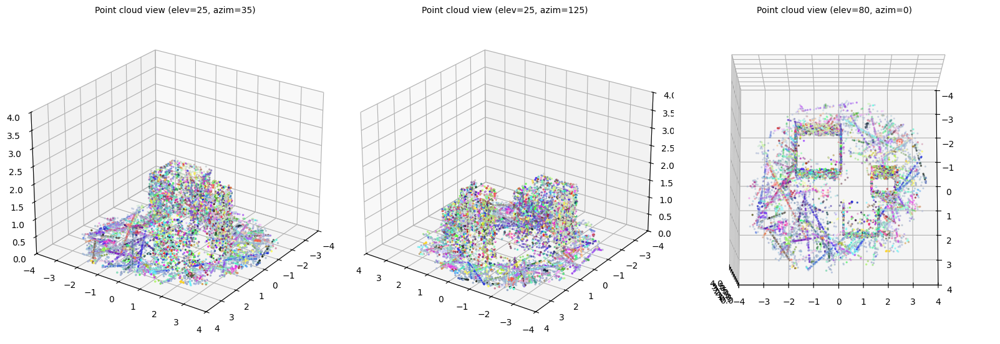

In [19]:
import open3d as o3d
P = np.array([p.xyz for p in rec.points3D.values()]); Col = np.array([p.color for p in rec.points3D.values()]) / 255.0
P = (s_ * (R_ @ P.T)).T + t_                           # into the ground-truth world frame
pcd = o3d.geometry.PointCloud(); pcd.points = o3d.utility.Vector3dVector(P); pcd.colors = o3d.utility.Vector3dVector(Col)
n0 = len(pcd.points)
pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)
pcd, _ = pcd.remove_radius_outlier(nb_points=6, radius=0.35)
print(f"Point cloud: {n0} points -> {len(pcd.points)} after outlier removal")
o3d.io.write_point_cloud(f"{OUT}/pointcloud.ply", pcd)

pts, cols = np.asarray(pcd.points), np.asarray(pcd.colors)
fig = plt.figure(figsize=(16, 5.5))
for k, (el, az) in enumerate([(25, 35), (25, 125), (80, 0)]):
    ax = fig.add_subplot(1, 3, k+1, projection="3d")
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=cols, s=2); ax.view_init(el, az)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_zlim(0, 4); ax.set_title(f"Point cloud view (elev={el}, azim={az})")
plt.tight_layout(); plt.savefig(f"{OUT}/q4_pointcloud.png", bbox_inches="tight"); plt.show()

Mesh: 21064 vertices, 41530 triangles, watertight=False
[Open3D WARNING] Write OBJ can not include triangle normals.


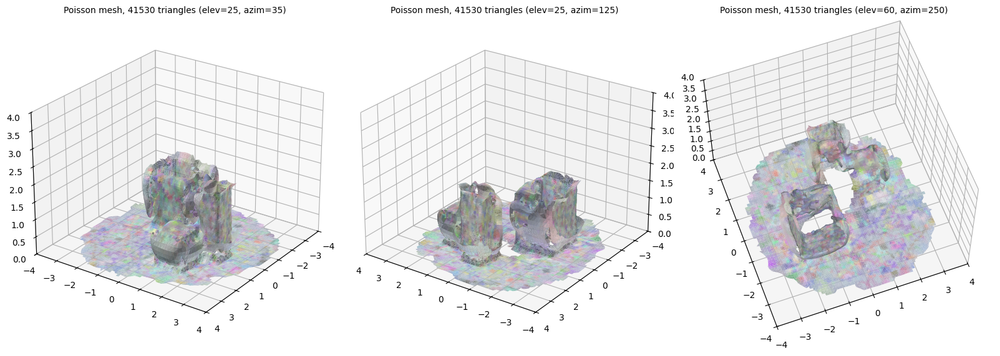

In [20]:
# ---- Poisson surface reconstruction -> triangle mesh ----
pcd.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=0.4, max_nn=40))
cam_c = gt_centres.mean(0) + np.array([0, 0, 6])                        # orient normals towards the cameras/viewer side
pcd.orient_normals_towards_camera_location(cam_c)
mesh, dens = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=7)
dens = np.asarray(dens); mesh.remove_vertices_by_mask(dens < np.quantile(dens, 0.08))   # trim low-support surface
mesh = mesh.crop(pcd.get_axis_aligned_bounding_box().scale(1.05, pcd.get_axis_aligned_bounding_box().get_center()))
mesh.remove_degenerate_triangles(); mesh.remove_unreferenced_vertices(); mesh.compute_vertex_normals()
print(f"Mesh: {len(mesh.vertices)} vertices, {len(mesh.triangles)} triangles, watertight={mesh.is_watertight()}")
o3d.io.write_triangle_mesh(f"{OUT}/mesh_poisson.ply", mesh)
o3d.io.write_triangle_mesh(f"{OUT}/mesh_poisson.obj", mesh)

V_, F_ = np.asarray(mesh.vertices), np.asarray(mesh.triangles)
fc = np.asarray(mesh.vertex_colors)[F_].mean(1) if mesh.has_vertex_colors() else np.full((len(F_), 3), 0.7)
tri = V_[F_]; nrm = np.cross(tri[:, 1]-tri[:, 0], tri[:, 2]-tri[:, 0]); nrm /= (np.linalg.norm(nrm, axis=1, keepdims=True) + 1e-12)
light = np.array([0.4, -0.5, 0.8]); light /= np.linalg.norm(light)
shade = 0.45 + 0.55*np.abs(nrm @ light)                       # simple Lambert shading so the 3D shape is visible
fcs = np.clip(fc*0.6 + 0.4, 0, 1) * shade[:, None]
fig = plt.figure(figsize=(16, 5.5))
for k, (el, az) in enumerate([(25, 35), (25, 125), (60, 250)]):
    ax = fig.add_subplot(1, 3, k+1, projection="3d")
    order = np.argsort((tri.mean(1) @ np.array([np.cos(np.deg2rad(az)), np.sin(np.deg2rad(az)), 0.0]))) # rough depth sort
    ax.add_collection3d(Poly3DCollection(tri[order], facecolors=fcs[order], edgecolor="none", linewidth=0)); ax.view_init(el, az)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_zlim(0, 4); ax.set_title(f"Poisson mesh, {len(F_)} triangles (elev={el}, azim={az})")
plt.tight_layout(); plt.savefig(f"{OUT}/q4_mesh.png", bbox_inches="tight"); plt.show()

In [21]:
# distance of every reconstructed point to the closest true surface (ground plane or one of the 3 boxes)
boxes = [(-1.2, -0.8, 0.9, 1.6), (1.4, 0.9, 0.7, 1.0), (0.2, 1.8, 0.5, 2.0)]
def dist_to_box(p, cx, cy, s, h):
    lo, hi = np.array([cx-s, cy-s, 0]), np.array([cx+s, cy+s, h])
    out = np.maximum(np.maximum(lo-p, p-hi), 0); dout = np.linalg.norm(out, axis=1)
    din = np.min(np.minimum(p-lo, hi-p), axis=1); return np.where(dout > 0, dout, din)
dg = np.abs(pts[:, 2])
db_ = np.min([dist_to_box(pts, *b) for b in boxes], axis=0)
dmin = np.minimum(dg, db_)
print(f"Median distance to the true surface: {np.median(dmin)*100:.2f} cm  |  90th percentile: {np.percentile(dmin, 90)*100:.2f} cm  |  inliers (<5 cm): {np.mean(dmin < 0.05)*100:.1f}%")
print("Points on ground plane:", int(np.sum(dg < 0.05)), "| points on boxes:", int(np.sum(db_ < 0.05)), "| total:", len(pts))

Median distance to the true surface: 0.18 cm  |  90th percentile: 0.72 cm  |  inliers (<5 cm): 99.8%
Points on ground plane: 6282 | points on boxes: 4391 | total: 10457
